# 0 Setup

In [32]:
from pathlib import Path
import sys

repo_path = Path.cwd().resolve()
if repo_path.name == 'notebooks':
    repo_path = repo_path.parent
sys.path.insert(0, str(repo_path))

from src.config import SAMPLE_SUBMISSION, TEST_RAW, TRAIN_RAW, repo_root

print(f'Repository root: {repo_root()}')
for raw_path in (TRAIN_RAW, TEST_RAW, SAMPLE_SUBMISSION):
    print(f'{raw_path.name} exists: {raw_path.exists()}')

Repository root: C:\Users\SKY\Documents\Pink Ai
pinkai_train.csv exists: True
pinkai_test.csv exists: True
sample_submission.csv exists: True


# 1 Load and inspect

Load both raw files as text, preserving cell values.

In [33]:
from IPython.display import display

from src.load import load_test, load_train
from src.inspect_data import (
    category_values,
    comma_decimal_count,
    date_samples,
    empty_cell_counts,
    id_report,
    label_counts,
    measurement_columns,
    non_numeric_cells,
    numeric_ranges,
    odd_column_names,
    shape_summary,
)

train = load_train()
test = load_test()
measurement_cols = measurement_columns(train)["column"].tolist()
print(f"Loaded train: {train.shape}; test: {test.shape}; measurement columns: {len(measurement_cols)}")

Loaded train: (9000, 38); test: (3000, 37); measurement columns: 30


Compare row and column counts and file-specific columns.

In [34]:
display(shape_summary(train, test))

{'train_shape': (9000, 38),
 'test_shape': (3000, 37),
 'train_only_columns': ['diagnosis'],
 'test_only_columns': []}

List column names that do not match lowercase letters and underscores.

In [35]:
print("Train odd column names")
display(odd_column_names(train))
print("Test odd column names")
display(odd_column_names(test))

Train odd column names


,column_name
0,Texture_Mean
1,perimeter mean
2,concave points_se
3,AREA_WORST


Test odd column names


,column_name
0,Texture_Mean
1,perimeter mean
2,concave points_se
3,AREA_WORST


Count each raw diagnosis spelling in the training file.

In [38]:
display(label_counts(train).head(15))

,raw_value,count
0,benign,1078
1,Benign,1074
2,B,1066
3,0,1020
4,B,979
5,M,740
6,1,700
7,malignant,627
8,MALIGNANT,626
9,m,618


Count blank, whitespace-only, and literal nan cells by column.

In [37]:
print("Train empty-like cells")
display(empty_cell_counts(train).head(15))
print("Test empty-like cells")
display(empty_cell_counts(test).head(15))

Train empty-like cells


,column,empty_count,empty_percent
0,notes,4297,47.744444
1,smoothness_se,539,5.988889
2,smoothness_mean,534,5.933333
3,smoothness_worst,528,5.866667
4,AREA_WORST,298,3.311111
5,compactness_worst,295,3.277778
6,fractal_dimension_mean,294,3.266667
7,symmetry_worst,289,3.211111
8,fractal_dimension_se,283,3.144444
9,texture_worst,282,3.133333


Test empty-like cells


,column,empty_count,empty_percent
0,notes,1448,48.266667
1,smoothness_worst,180,6.000000
2,smoothness_mean,172,5.733333
3,smoothness_se,150,5.000000
4,area_mean,112,3.733333
5,perimeter_worst,106,3.533333
6,concavity_worst,103,3.433333
7,fractal_dimension_se,99,3.300000
8,radius_worst,98,3.266667
9,symmetry_worst,98,3.266667


Count measurement cells written with comma decimal separators.

In [39]:
print("Train comma-decimal counts")
display(comma_decimal_count(train, measurement_cols).head(15))
print("Test comma-decimal counts")
display(comma_decimal_count(test, measurement_cols).head(15))

Train comma-decimal counts


,column,comma_decimal_count
0,radius_mean,324
1,Texture_Mean,332
2,perimeter mean,297
3,area_mean,317
4,smoothness_mean,314
5,compactness_mean,360
6,concavity_mean,331
7,concave_points_mean,345
8,symmetry_mean,300
9,fractal_dimension_mean,338


Test comma-decimal counts


,column,comma_decimal_count
0,radius_mean,101
1,Texture_Mean,107
2,perimeter mean,115
3,area_mean,108
4,smoothness_mean,96
5,compactness_mean,127
6,concavity_mean,106
7,concave_points_mean,109
8,symmetry_mean,105
9,fractal_dimension_mean,111


Count unparseable non-empty measurement values and show examples.

In [40]:
print("Train non-numeric measurement values")
display(non_numeric_cells(train, measurement_cols).head(15))
print("Test non-numeric measurement values")
display(non_numeric_cells(test, measurement_cols).head(15))

Train non-numeric measurement values


,column,non_numeric_count,example_bad_values
0,radius_mean,142,"[n/a, ?, NULL, missing, unknown]"
1,Texture_Mean,163,"[?, N/A, n/a, unknown, --]"
2,perimeter mean,154,"[unknown, -, --, NULL, n/a]"
3,area_mean,680,"[1,419.5, 1,067.1, 1,310.0, 1,041.0, 1,062.7]"
4,smoothness_mean,161,"[missing, n/a, N/A, unknown, NULL]"
5,compactness_mean,159,"[NULL, unknown, N/A, missing, -]"
6,concavity_mean,156,"[missing, unknown, N/A, -, n/a]"
7,concave_points_mean,172,"[NULL, n/a, N/A, -, --]"
8,symmetry_mean,171,"[NULL, unknown, -, N/A, --]"
9,fractal_dimension_mean,198,"[-, ?, n/a, missing, N/A]"


Test non-numeric measurement values


,column,non_numeric_count,example_bad_values
0,radius_mean,52,"[NULL, -, ?, unknown, --]"
1,Texture_Mean,60,"[--, NULL, n/a, unknown, ?]"
2,perimeter mean,60,"[unknown, missing, N/A, ?, --]"
3,area_mean,141,"[missing, 1,080.5, 1,038.2, 1,233.7, 1,579.6]"
4,smoothness_mean,62,"[?, n/a, N/A, -, unknown]"
5,compactness_mean,60,"[missing, NULL, n/a, -, ?]"
6,concavity_mean,61,"[unknown, -, N/A, --, NULL]"
7,concave_points_mean,53,"[missing, unknown, --, -, ?]"
8,symmetry_mean,55,"[n/a, --, ?, -, missing]"
9,fractal_dimension_mean,76,"[missing, N/A, n/a, ?, NULL]"


Report repeated IDs, exact duplicate rows, unique IDs, and train-test overlap.

In [41]:
display(id_report(train, test))

{'train_duplicate_patient_id_rows': 346,
 'test_duplicate_patient_id_rows': 116,
 'train_identical_duplicate_rows': 173,
 'test_identical_duplicate_rows': 58,
 'train_unique_patient_ids': 8654,
 'test_unique_patient_ids': 2884,
 'shared_patient_ids': [],
 'shared_patient_id_count': 0}

Show raw values of center and biopsy_followup_code in both files.

In [42]:
for column in ("center", "biopsy_followup_code"):
    print(f"Train {column}")
    display(category_values(train, column).head(15))
    print(f"Test {column}")
    display(category_values(test, column).head(15))

Train center


,raw_value,count
0,Site A,3308
1,Site B,2835
2,Site C,1977
3,SITE A,166
4,SITE B,149
5,SITE C,85
6,Site B,36
7,Site A,35
8,Site C,32
9,Site A,31


Test center


,raw_value,count
0,Site A,1029
1,Site B,987
2,Site C,649
3,SITE A,64
4,SITE B,56
5,SITE C,36
6,Site B,15
7,\tSite A,15
8,Site B,14
9,Site B,14


Train biopsy_followup_code


,raw_value,count
0,ROUTINE,5362
1,ONC-REF,3449
2,RECHECK,189


Test biopsy_followup_code


,raw_value,count
0,ROUTINE,2300
1,ONC-REF,625
2,RECHECK,75


Sample raw exam dates reproducibly from each file.

In [43]:
print("Train exam_date sample")
display(date_samples(train, n=15))
print("Test exam_date sample")
display(date_samples(test, n=15))

Train exam_date sample


,exam_date
0,17/09/2025
1,13-Apr-26
2,30-Nov-25
3,2026-06-06
4,"November 13, 2025"
5,2026-06-15
6,12-Nov-25
7,2025-05-02
8,16/01/2026
9,27-May-25


Test exam_date sample


,exam_date
0,27-Feb-26
1,"January 26, 2026"
2,07-May-26
3,25-Feb-25
4,28/11/2025
5,27/05/2026
6,29/01/2026
7,30-Jun-26
8,09-Dec-25
9,2026-09-16


List measurement columns and inspect training numeric ranges for unusual units.

In [44]:
print(f"Measurement columns ({len(measurement_cols)})")
print(measurement_cols)
display(numeric_ranges(train, measurement_cols).head(15))

Measurement columns (30)
['radius_mean', 'Texture_Mean', 'perimeter mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'AREA_WORST', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,column,min,p01,median,p99,max
0,radius_mean,0.500000,1.057204,13.341250,24.912284,2.030953e+04
1,Texture_Mean,9.468410,11.139467,18.892800,31.972451,2.916305e+04
2,perimeter mean,32.761600,53.484908,89.230000,736.136000,5.603466e+05
3,area_mean,-452.200000,84.506000,551.500000,1830.861000,1.272592e+06
4,smoothness_mean,0.052706,0.068676,0.095923,0.139117,1.159700e+02
5,compactness_mean,0.014003,0.033932,0.095090,0.284765,2.846800e+02
6,concavity_mean,0.000000,0.000000,0.071199,0.391361,3.175000e+02
7,concave_points_mean,0.000000,0.000000,0.037408,0.182826,1.640000e+02
8,symmetry_mean,0.094759,0.129867,0.179513,0.266970,2.067900e+02
9,fractal_dimension_mean,0.046436,0.051028,0.061602,0.090196,7.408310e+01


## What we saw

### 1. Size and structure
- Train has 9,000 rows and 38 columns. Test has 3,000 rows and 37 columns. The only column test lacks is `diagnosis` (the answer), which is correct.
- 30 columns are the real measurements (10 properties x mean / se / worst). The other columns are admin: `patient_id`, `exam_date`, `center`, `age`, `biopsy_followup_code`, `notes`, `sample_ref`.
- Four column names are inconsistent: `Texture_Mean`, `perimeter mean`, `concave points_se`, `AREA_WORST`. Same problem in train and test. We rename everything to lowercase_with_underscores.

### 2. The answer column (`diagnosis`) is written many ways
- Benign appears as `B`, ` B`, `Benign`, `benign `, `0` and more. Malignant appears as `M`, `m`, `MALIGNANT`, `malignant`, `1` and more.
- The top 10 spellings cover about 8,500 of the 9,000 rows, so a few rarer spellings are hidden further down. We must check them all when we clean.
- Roughly 4 in 10 patients are malignant, 6 in 10 benign. This is not extremely imbalanced.

### 3. Numbers are stored as messy text
- **Comma as decimal point:** `1,02967` means 1.02967. It appears in hundreds of cells in almost every measurement column (e.g. 360 in `compactness_mean`).
- **Comma as thousands separator:** `1,419.5` in `area_mean` means 1419.5. This is the OPPOSITE meaning of the comma! If we blindly replace "," with ".", we break these (it becomes `1.419.5`). Rule needed: if a value contains both a comma and a dot, remove the comma; if it has only a comma, treat it as the decimal point.
- **Fake missing values:** `n/a`, `?`, `NULL`, `missing`, `unknown`, `-`, `--`. All of these must become real missing values (NaN).

### 4. Missing values
- `smoothness_mean`, `smoothness_se`, `smoothness_worst` are each missing in about 6% of rows, the highest among measurements. Other measurements have fewer gaps.
- `notes` is empty in about 48% of rows (both files) and also contains both English and Arabic text.
- Missing values will be filled using training-file statistics only (never test).

### 5. Impossible and wrong-unit values (the "wrong units" trap)
- Normal `area_mean` is around 550 (median) and 99% of values are below about 1,830. But the maximum is 1,272,592 and the minimum is NEGATIVE (-452). Area cannot be negative.
- `radius_mean`: median 13.3, maximum 20,309. `perimeter mean`: median 89, maximum 560,346.
- So some rows were recorded in a different unit (values hugely too big), and some have sign errors. Plan: use the geometry link (perimeter ~ 2 x pi x radius, area ~ pi x radius^2) to detect these rows and repair them, not delete them. Note the size of the jump is not exactly the same in every column, so we must investigate before choosing the fix.

### 6. Duplicates
- Train: 8,654 unique patients in 9,000 rows, so 346 extra rows. Of those, 173 are exact copies, and the other 173 share a `patient_id` but have different values (the same patient entered twice with different numbers).
- Test: 2,884 unique patients in 3,000 rows (116 extra, 58 exact copies, 58 with conflicting values). This is why the submission needs exactly 2,884 rows, one per unique ID.
- No patient appears in both train and test. Good, no cheating possible there.
- For validation we must keep all rows of a patient on the same side (group by `patient_id`).

### 7. Dates and centres
- Dates come in at least four formats: `2026-06-06`, `17/09/2025`, `13-Apr-26`, `November 13, 2025`. Slash dates may be day/month or month/day, which can be confusing. We need a consistent rule.
- `center` is Site A / B / C, but with upper-case and extra-space variants (`SITE A`, ` Site B `). After cleaning there should be exactly 3 centres.

### 8. Signs that the test set is different from train (important for the threshold)
- `biopsy_followup_code`: in train, ONC-REF is 38% of rows (3,449 / 9,000) and ROUTINE is 60%. In test, ONC-REF is only about 21% (625 / 3,000) and ROUTINE about 77%.
- We already know ONC-REF goes with cancer (a likely leak, to be proved in Stage 5). If that holds, the test set has noticeably FEWER malignant cases than train. That means more of our predicted "M" would be false alarms, so precision would drop on test.
- Therefore: choose a threshold with a safety margin (aim for ~0.93-0.95 precision in validation, not 0.90), and also test how the model behaves under a lower share of malignant cases.
- Centre mix looks similar between train and test, so the difference is not mainly about centres.

### 9. Suspicious columns (to check in Stage 5)
- `biopsy_followup_code` (probable leak), `sample_ref` (lab tracking code), `notes` (free text, mixed languages).

### Things to do next (Stage 3 and 4)
1. Rename columns. 2. Parse numbers with the comma rule above and turn fake-missing text into NaN. 3. Standardise labels to 0/1 and centres to A/B/C. 4. Convert dates. 5. Fix negative and wrong-unit values by repair. 6. Handle duplicates (drop exact copies, decide what to do with conflicting ones). 7. Fill gaps using train-only statistics.

### Numbers to remember
9,000 / 3,000 rows | 30 measurement columns | 8,654 / 2,884 unique patients | 173 exact + 173 conflicting duplicates in train | about 6% missing smoothness | about 48% empty notes | 0 shared IDs | ONC-REF 38% in train vs 21% in test

# 2 Cleaning

## What we fixed (stage 3)

All fixes are fixed rules (nothing learned from data), so they were applied identically to train (9,000 rows) and test (3,000 rows). Raw files were never edited. Cleaned copies are in `data/clean/`.

1. **Column names:** 4 inconsistent names (`Texture_Mean`, `perimeter mean`, `concave points_se`, `AREA_WORST`) renamed to lowercase_with_underscores. All 38 columns now match the data dictionary.
2. **Fake missing values:** text such as `n/a` (1,312), `?` (614), `null` (650), `missing` (617), `unknown` (623), `-` (721) and `--` (681) turned into real NaN in the numeric columns. Blank cells were also converted. Nothing was left unparseable afterwards.
3. **Numbers stored as text:** 9,919 cells with a decimal comma (`1,02967` -> 1.02967) and 1,389 cells with a thousands comma (`1,419.5` -> 1419.5), each handled by its own rule. The rule: a comma plus a dot means thousands separator, a comma alone means decimal point.
4. **Labels:** 9 spellings of the diagnosis mapped to two classes, with 0 unrecognised values. Train = 5,494 benign (61.0%) and 3,506 malignant (39.0%).
5. **Centres:** upper-case and whitespace variants standardised to exactly 3 centres: Site A (3,655), Site B (3,150), Site C (2,195) in train.
6. **Dates:** 4+ formats converted to real dates. Slash dates are day/month/year, because 1,402 train slash dates have a first part above 12 and none has a second part above 12. 910 slash dates are fully ambiguous, but follow the same rule.

## Still open (to handle in Stage 4/5)
- **190 ambiguous commas in train (79 in test)**, e.g. `radius_mean = 1,127`, which was treated as 1.127. It could really be 1127 (a wrong-unit value). The geometry check (radius vs perimeter vs area) in Stage 4 will decide.
- **Dates:** 47 train dates are invalid calendar dates (now empty) and 45 are outside the expected range, such as 2099-12-31, which looks like a placeholder. We treat both as missing, not as real dates.
- **Missing values remain** (about 410-490 per measurement column, and about 700 in each smoothness column). They are filled in Stage 5 using train-only statistics.
- **Wrong units and negative values** (area down to -452, radius up to 20,309): not touched yet.
- **Duplicates** (173 exact copies and 173 conflicting repeats in train): not touched yet.

In [45]:
import pandas as pd

from src.clean import clean_stage3, write_cleaning_log
from src.config import CLEAN_DIR

train_raw_stage3 = load_train()
test_raw_stage3 = load_test()

print("TRAIN Stage 3 diagnostics")
train_stage3, train_stage3_log = clean_stage3(train_raw_stage3)
print("TEST Stage 3 diagnostics")
test_stage3, test_stage3_log = clean_stage3(test_raw_stage3)

print("Training Stage 3 log entries")
display(pd.DataFrame(train_stage3_log))
print("Training cleaned dataframe info")
train_stage3.info()
print("Training NaN count per column")
display(train_stage3.isna().sum().rename("nan_count").to_frame())

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train_stage3.to_csv(CLEAN_DIR / "train_stage3.csv", index=False)
test_stage3.to_csv(CLEAN_DIR / "test_stage3.csv", index=False)
write_cleaning_log(train_stage3_log)
print(f"Saved cleaned train and test files to {CLEAN_DIR}")

TRAIN Stage 3 diagnostics
Comma numbers: decimal-comma cells=9919; thousands-comma cells=1389.
Ambiguous comma cells treated as decimal: 190; first 10 (column=value): [('radius_mean', '1,127'), ('radius_mean', '15,185'), ('radius_mean', '15,889'), ('radius_mean', '14,488'), ('radius_mean', '20,737'), ('radius_mean', '14,657'), ('radius_mean', '19,749'), ('radius_mean', '21,761'), ('radius_mean', '12,705'), ('radius_mean', '10,942')]
Unparseable numeric cells set to NaN: 0; remaining non-numeric values (column, value): []
NaN diagnosis labels: 0
Final class counts (y): {np.int64(0): 5494, np.int64(1): 3506}; malignant=38.96%
Centre counts: {'Site A': 3655, 'Site B': 3150, 'Site C': 2195}
Slash-date ambiguity: first part > 12=1402; second part > 12=0; both <= 12=910.
Unparseable dates set to NaT: 47
Date range: min=2025-01-05 00:00:00; max=2099-12-31 00:00:00; outside 2024-01-01..2026-12-31=45
TEST Stage 3 diagnostics
Comma numbers: decimal-comma cells=3320; thousands-comma cells=290.
Am

,problem,columns,rows_affected,fix,why
0,Inconsistent column names,"texture_mean, perimeter_mean, concave_points_s...",0,Renamed 4 column headers; no data cells changed.,Consistent lowercase names with underscores ma...
1,Surrounding whitespace in text fields,"patient_id, exam_date, center, age, biopsy_fol...",3630,Stripped surrounding whitespace from 3630 cell...,Whitespace obscures otherwise identical identi...
2,Fake missing-value text in numeric fields,"radius_mean, radius_se, radius_worst, texture_...",14111,Replaced 14111 cells with NaN; counts by token...,These fixed missing-value spellings are not nu...
3,Numeric fields stored as text,"radius_mean, radius_se, radius_worst, texture_...",264889,Converted 264889 cells to float; decimal-comma...,The fixed parsing rules normalize number forma...
4,Inconsistent diagnosis labels,"diagnosis, y",15072,Standardized known labels to B/M and created i...,Only the specified benign and malignant spelli...
5,Inconsistent centre spelling or case,center,421,"Stripped and uppercased values, then standardi...",The data dictionary defines exactly three clin...
6,Exam dates stored in mixed formats,"exam_date, exam_date_raw",17953,"Parsed valid dates, retained original text in ...",Explicit formats and measured slash-date evide...


Training cleaned dataframe info
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   patient_id               9000 non-null   str           
 1   exam_date                8953 non-null   datetime64[us]
 2   center                   9000 non-null   str           
 3   age                      9000 non-null   float64       
 4   biopsy_followup_code     9000 non-null   str           
 5   radius_mean              8592 non-null   float64       
 6   texture_mean             8570 non-null   float64       
 7   perimeter_mean           8585 non-null   float64       
 8   area_mean                8553 non-null   float64       
 9   smoothness_mean          8305 non-null   float64       
 10  compactness_mean         8588 non-null   float64       
 11  concavity_mean           8583 non-null   float64       
 12  concave_point

,nan_count
patient_id,0
exam_date,47
center,0
age,0
biopsy_followup_code,0
radius_mean,408
texture_mean,430
perimeter_mean,415
area_mean,447
smoothness_mean,695


Saved cleaned train and test files to C:\Users\SKY\Documents\Pink Ai\data\clean


## Stage 4 structural repairs

Diagnose geometry before applying sign, comma, unit, duplicate, and basic-column repairs.

In [46]:
import importlib

import src.repair
from IPython.display import Markdown, display

importlib.reload(src.repair)
diagnose_geometry = src.repair.diagnose_geometry

geometry_diagnostics = diagnose_geometry(train_stage3)
for table_name, caption in (
    ("ratio_distribution", "Rounded log10 geometry scale deviations by triple and ratio."),
    ("geometry_counts", "Rows with normal ratios, a single-column scale signature, or incomplete geometry."),
    ("stratified_counts", "Geometry categories by centre and exam month."),
    ("negative_counts", "Negative values in each measurement column."),
    ("ordering_counts", "Worst-below-mean and likely radius/perimeter/area swaps."),
):
    display(Markdown(caption))
    display(geometry_diagnostics[table_name].head(15))

Rounded log10 geometry scale deviations by triple and ratio.

,suffix,ratio,rounded_log10_scale,rows,log10_min,log10_median,log10_max
0,mean,perimeter/radius,-3,8,-3.003799,-2.989556,-2.968714
1,mean,perimeter/radius,-2,15,-2.000242,-1.985796,-1.973488
2,mean,perimeter/radius,-1,2,-1.000329,-0.974984,-0.949639
3,mean,perimeter/radius,0,7339,-0.030767,0.013347,0.067176
4,mean,perimeter/radius,1,774,0.566250,1.009389,1.149091
5,mean,perimeter/radius,2,29,1.790145,2.005863,2.046310
6,mean,perimeter/radius,3,25,2.713281,3.010777,3.047448
7,mean,perimeter/radius,4,3,3.821878,4.000053,4.013040
8,mean,area/radius^2,-6,9,-6.017597,-6.009140,-5.996131
9,mean,area/radius^2,-4,15,-4.026256,-4.006363,-3.983162


Rows with normal ratios, a single-column scale signature, or incomplete geometry.

,suffix,category,rows
0,mean,area_off,26
1,mean,incomplete,1226
2,mean,normal,6932
3,mean,other_inconsistent,144
4,mean,perimeter_off,39
5,mean,radius_off,633
6,se,area_off,7614
7,se,incomplete,1270
8,se,other_inconsistent,114
9,se,radius_off,2


Geometry categories by centre and exam month.

,suffix,by,group,category,rows
0,mean,center,Site A,area_off,13
1,mean,center,Site A,incomplete,500
2,mean,center,Site A,normal,2823
3,mean,center,Site A,other_inconsistent,39
4,mean,center,Site A,perimeter_off,15
5,mean,center,Site A,radius_off,265
6,mean,center,Site B,area_off,7
7,mean,center,Site B,incomplete,436
8,mean,center,Site B,normal,2423
9,mean,center,Site B,other_inconsistent,67


Negative values in each measurement column.

,column,negative_values
0,radius_mean,0
1,texture_mean,0
2,perimeter_mean,0
3,area_mean,12
4,smoothness_mean,0
5,compactness_mean,0
6,concavity_mean,0
7,concave_points_mean,0
8,symmetry_mean,0
9,fractal_dimension_mean,0


Worst-below-mean and likely radius/perimeter/area swaps.

,check,rows
0,radius > perimeter (mean),25
1,perimeter > area (mean),200
2,radius > perimeter (se),43
3,perimeter > area (se),56
4,radius > perimeter (worst),38
5,perimeter > area (worst),56
6,radius_worst < radius_mean,642
7,perimeter_worst < perimeter_mean,189
8,area_worst < area_mean,65


Stage 4 self-check: remaining negative measurements=0
mean normal geometry ratio share=0.9818 (7291/7426)
se normal geometry ratio share=0.0000 (0/7381)
worst normal geometry ratio share=0.9988 (7312/7321)
radius_mean min/median/max=0.888295/13.6573/30.9854
perimeter_mean min/median/max=32.7616/89.15035/560346.63
area_mean min/median/max=0.0/570.4/1849858.0
Stage 4 self-check: remaining negative measurements=0
mean normal geometry ratio share=0.9825 (2420/2463)
se normal geometry ratio share=0.0000 (0/2467)
worst normal geometry ratio share=0.9984 (2444/2448)
radius_mean min/median/max=0.929099/12.9446/1234.0
perimeter_mean min/median/max=32.3033/84.3973/135557.14
area_mean min/median/max=0.0/513.95/2619.8


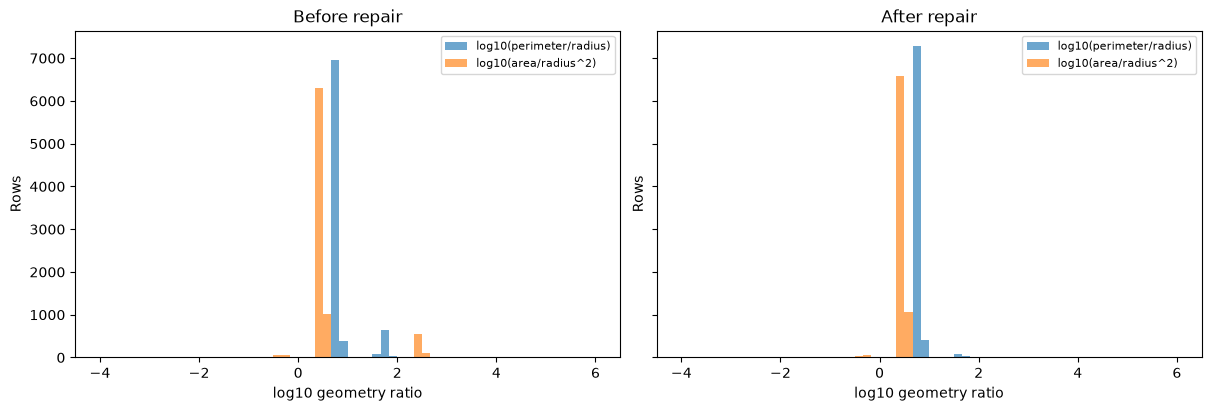

Saved geometry comparison: C:\Users\SKY\Documents\Pink Ai\evidence\figures\geometry_before_after.png
Training Stage 4 log entries and counts


,problem,columns,rows_affected,fix,why
0,Negative measurement values,"area_mean, area_se, area_worst",40,Absolute-value repairs=1; set to NaN=39; per c...,Absolute values were kept only when the availa...
1,Ambiguous comma-only numeric values,"radius_mean, radius_se, radius_worst, texture_...",189,Kept decimal=165; switched to thousands=0; set...,Raw text was re-matched; geometry was used for...
2,Power-of-ten geometry unit errors,radius/perimeter/area mean and worst; SE branc...,1520,Rows by case: radius=1371; perimeter=68; area=...,Only unique powers-of-ten corrections that res...
3,Repeated patient records,patient_id plus differing columns,692,"Before merge: exact duplicate rows=173, repeat...",One record per patient was retained by fewest ...
4,"Basic age, identifier, and date checks","age, patient_id, exam_date",49,Age outside 18-100 set to NaN=8; non-digit pat...,Only explicit age/date validity bounds were ap...


Negative measurement values: Absolute-value repairs=1; set to NaN=39; per column: area_mean: abs=1, NaN=11; area_se: abs=0, NaN=10; area_worst: abs=0, NaN=18.
Ambiguous comma-only numeric values: Kept decimal=165; switched to thousands=0; set to NaN=25; per column: compactness_worst: decimal=2, thousands=0, NaN=0; concave_points_worst: decimal=1, thousands=0, NaN=0; concavity_mean: decimal=1, thousands=0, NaN=0; concavity_se: decimal=2, thousands=0, NaN=0; concavity_worst: decimal=1, thousands=0, NaN=0; fractal_dimension_mean: decimal=1, thousands=0, NaN=0; fractal_dimension_worst: decimal=1, thousands=0, NaN=0; perimeter_mean: decimal=14, thousands=0, NaN=2; perimeter_se: decimal=12, thousands=0, NaN=8; perimeter_worst: decimal=14, thousands=0, NaN=3; radius_mean: decimal=21, thousands=0, NaN=3; radius_se: decimal=0, thousands=0, NaN=5; radius_worst: decimal=20, thousands=0, NaN=4; smoothness_mean: decimal=3, thousands=0, NaN=0; smoothness_worst: decimal=2, thousands=0, NaN=0; symmetr

In [47]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import src.repair

importlib.reload(src.repair)
repair_stage4 = src.repair.repair_stage4

train_stage4, train_stage4_log = repair_stage4(
    train_stage3,
    train_raw_stage3,
    has_label=True,
)
test_stage4, test_stage4_log = repair_stage4(
    test_stage3,
    test_raw_stage3,
    has_label=False,
    train_reference=train_stage3,
)


def _log_geometry_ratios(frame):
    radius = pd.to_numeric(frame["radius_mean"], errors="coerce")
    perimeter = pd.to_numeric(frame["perimeter_mean"], errors="coerce")
    area = pd.to_numeric(frame["area_mean"], errors="coerce")
    valid_perimeter = radius.gt(0) & perimeter.gt(0)
    valid_area = radius.gt(0) & area.gt(0)
    return (
        np.log10(perimeter[valid_perimeter] / radius[valid_perimeter]),
        np.log10(area[valid_area] / radius[valid_area] ** 2),
    )


before_perimeter_ratio, before_area_ratio = _log_geometry_ratios(train_stage3)
after_perimeter_ratio, after_area_ratio = _log_geometry_ratios(train_stage4)
figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for axis, title, perimeter_ratio, area_ratio in (
    (axes[0], "Before repair", before_perimeter_ratio, before_area_ratio),
    (axes[1], "After repair", after_perimeter_ratio, after_area_ratio),
):
    axis.hist(perimeter_ratio, bins=60, range=(-4, 6), alpha=0.65, label="log10(perimeter/radius)")
    axis.hist(area_ratio, bins=60, range=(-4, 6), alpha=0.65, label="log10(area/radius^2)")
    axis.set_title(title)
    axis.set_xlabel("log10 geometry ratio")
    axis.set_ylabel("Rows")
    axis.legend(fontsize=8)
figure_path = repo_path / "evidence" / "figures" / "geometry_before_after.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=160)
plt.show()
print(f"Saved geometry comparison: {figure_path}")

print("Training Stage 4 log entries and counts")
display(pd.DataFrame(train_stage4_log))
for entry in train_stage4_log:
    print(f"{entry['problem']}: {entry['fix']}")
print("Test Stage 4 counts")
for entry in test_stage4_log:
    print(f"{entry['problem']}: {entry['fix']}")

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train_stage4.to_csv(CLEAN_DIR / "train_stage4.csv", index=False)
test_stage4.to_csv(CLEAN_DIR / "test_stage4.csv", index=False)
write_cleaning_log(train_stage3_log + train_stage4_log)
print(f"Saved Stage 4 train and test files to {CLEAN_DIR}")

## What we fixed (stage 4)

Structural problems (relationships between columns), repaired rather than deleted wherever possible. The same rules were applied to train and test.

1. **Wrong units (the biggest problem):** radius, perimeter and area describe the same shape, so perimeter/radius should be about 6.3 and area/radius^2 about 3.14. These ratios were broken in 1,454 train rows (16.9%) and 462 test rows (16.0%). Cause: one column recorded in the wrong unit, mostly radius off by a factor of 10 (likely cm instead of mm), plus some factors of 100 and 1000. We rescaled the odd column by the detected power of ten, only when that made the ratios normal. Cases (train, before merging): radius 1,371; perimeter 68; area 69; all three scaled together 5.
2. **Not concentrated:** unit errors are spread evenly over Site A / B / C (601 / 491 / 362 rows) and over all months, so they look like random data-entry errors.
3. **Unrepairable:** 170 train and 58 test cases had no safe correction, so the cell was set to missing for imputation, not guessed.
4. **Proof of repair:** consistent geometry in 98.2% of train rows (mean columns) and 99.9% (worst columns); test 98.3% and 99.8%. See evidence/figures/geometry_before_after.png.
5. **Ambiguous commas:** 190 train and 79 test values like "1,127" could be 1.127 or 1127. Checked against the geometry: all resolvable ones were decimals (165 train, 72 test); 25 train and 7 test could not be decided and were set to missing.
6. **Negative values:** 1 train value was a sign flip (repaired with its absolute value); 39 train and 21 test were set to missing. No negatives remain.
7. **Duplicates:** after the repairs, all repeated patient IDs were merged into one row per patient (kept the row with the fewest gaps, filled its gaps from the other copies). Exact duplicates: 173 train, 58 test. Train 9,000 -> 8,604 rows; test 3,000 -> 2,884 rows (one per patient, as the submission needs).
8. **Label conflicts:** 50 train patients had copies with opposite diagnoses. The true label is unknowable, so these patients (100 rows) were dropped. This is the only place we deleted.
9. **Not repaired:** the _se columns. They are standard errors, so the geometry check does not apply (area_se / radius_se^2 has a median around 240, not 3.14). Whether they hold unit errors in the flagged rows is still unchecked (Stage 5).
10. **Traceability:** the flag_ columns record which rows were changed (flag_unit_fixed, flag_sign_fixed, flag_comma_resolved, flag_merged_duplicate). They must NOT be used as model inputs.

# 3 Suspicious columns

Score requested suspicious columns with patient-grouped five-fold ROC-AUC.

In [48]:
from src.audit import (
    followup_vs_label,
    measurement_signal,
    notes_vs_label,
    sample_ref_vs_label,
    se_geometry_check,
    single_column_power,
    train_test_shift,
)
from src.config import CLEAN_DIR

audit_train = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
audit_test = pd.read_csv(CLEAN_DIR / "test_stage4.csv", parse_dates=["exam_date"])
display(single_column_power(audit_train))

,feature,auc,auc_std
0,biopsy_followup_code,0.976557,0.006830
1,age,0.571619,0.015894
2,center,0.514053,0.015605
3,exam_date_month,0.510121,0.016038
4,notes_present,0.505794,0.011015
5,notes_language,0.504119,0.008668
6,flag_unit_fixed,0.503532,0.003182
7,flag_comma_resolved,0.502795,0.004650
8,flag_sign_fixed,0.499905,0.000190
9,n_missing,0.497082,0.005509


Check biopsy follow-up codes against benign and malignant outcomes.

In [49]:
display(followup_vs_label(audit_train))

y,biopsy_followup_code,benign_count,malignant_count,count,benign_pct,malignant_pct
0,ONC-REF,115,3189,3304,3.480630,96.519370
1,RECHECK,104,72,176,59.090909,40.909091
2,ROUTINE,5045,79,5124,98.458236,1.541764


Show the most common notes and the malignant percentage for each.

In [50]:
display(notes_vs_label(audit_train))

,notes_text,count,malignant_pct
0,repeat sample requested,291,37.113402
1,slide reviewed,284,42.605634
2,"poor fixation, re-stain",282,39.007092
3,follow-up scheduled,281,39.145907
4,عينة جيدة,275,39.272727
5,جودة الصبغة منخفضة,275,39.272727
6,"second opinion, pending",273,38.095238
7,الشريحة غير واضحة,269,33.457249
8,أعيد الفحص,265,39.245283
9,"referred, see chart",264,40.909091


Compare sample-reference letters and numeric references with the diagnosis.

In [51]:
display(sample_ref_vs_label(audit_train))

,item,value,count,malignant_pct,correlation
0,sample_ref_letter,G,1055,41.327014,NaN
1,sample_ref_letter,C,1116,39.247312,NaN
2,sample_ref_letter,A,1112,37.140288,NaN
3,sample_ref_letter,E,1065,40.000000,NaN
4,sample_ref_letter,H,1057,38.789026,NaN
5,sample_ref_letter,F,1031,39.670223,NaN
6,sample_ref_letter,D,1061,37.323280,NaN
7,sample_ref_letter,B,1107,37.217706,NaN
8,sample_ref_number_vs_y,all,8604,NaN,0.013263


Compare standard-error medians and ratios for unit-fixed versus unchanged rows.

In [52]:
display(se_geometry_check(audit_train))

,flag_unit_fixed,radius_se,perimeter_se,area_se,area_se/radius_se^2,perimeter_se/radius_se
0,False,0.341968,2.32644,27.1,241.689327,6.909614
1,True,0.336755,2.33303,26.4,238.213152,6.865098


Compare train and test medians, category shares, and the unit-repair flag.

In [53]:
display(train_test_shift(audit_train, audit_test))

,metric,column,category,median_train,median_test,shift_iqr_train,percent_train,percent_test
0,median,concave_points_worst,,0.105063,0.084495,-0.219064,NaN,NaN
1,median,concavity_worst,,0.233188,0.179100,-0.209225,NaN,NaN
2,median,compactness_mean,,0.095090,0.082159,-0.202636,NaN,NaN
3,median,concavity_mean,,0.071481,0.052659,-0.184157,NaN,NaN
4,median,perimeter_worst,,101.710000,94.860500,-0.178481,NaN,NaN
5,median,radius_worst,,15.462800,14.417500,-0.177526,NaN,NaN
6,median,concave_points_mean,,0.037407,0.028658,-0.172395,NaN,NaN
7,median,radius_mean,,13.657300,12.944600,-0.161979,NaN,NaN
8,median,perimeter_mean,,89.150350,84.397300,-0.156811,NaN,NaN
9,median,compactness_worst,,0.218617,0.189092,-0.155903,NaN,NaN


Rank individual measurement columns by direction-adjusted ROC-AUC.

In [54]:
display(measurement_signal(audit_train))

,column,auc,rows
0,concave_points_mean,0.895685,8179
1,concave_points_worst,0.894466,8145
2,radius_worst,0.889688,8176
3,area_worst,0.888072,8130
4,perimeter_worst,0.881023,8159
5,radius_mean,0.858626,8207
6,concavity_mean,0.851823,8200
7,concavity_worst,0.848009,8155
8,area_se,0.847027,8200
9,area_mean,0.845974,8158


## What we found (stage 5)

**Dropped columns and the evidence**
1. `biopsy_followup_code` is a leak. Alone it gives a cross-validated AUC of 0.977. ONC-REF -> 96.5% malignant (3,304 rows), ROUTINE -> 1.5% malignant (5,124 rows). It records a decision made after the diagnosis, so we drop it.
2. `sample_ref` (letter AUC 0.497, number AUC 0.488, correlation with label 0.013), `notes` (AUC 0.506 for present/empty, 0.504 for language; malignant share between 33% and 43% for every text, 38.2% when empty) carry no signal. We drop them: they are noise and notes mix English and Arabic.
3. `center`, `exam_date` month, `patient_id`: AUC 0.51 or no meaning. Dropped so the model cannot depend on a site or a calendar effect.
4. The four repair flags and `n_missing` all score about 0.50. Our repairs left no hidden clues, and missing values look random. Flags are kept only for traceability, not as features.

**Which columns carry the signal**
5. Best single measurements: concave_points_mean (AUC 0.896), concave_points_worst (0.895), radius_worst (0.890), area_worst (0.888), perimeter_worst (0.881). This matches medical intuition: larger, more irregular nuclei -> malignant.
6. `age` is a weak but real signal (AUC 0.57), so we keep it.

**Standard-error columns**
7. In rows where we fixed units, radius_se / perimeter_se / area_se have the same medians as in untouched rows (e.g. area_se 26.4 vs 27.1), so the _se columns do not carry unit errors and were left alone.

**Train vs test differences (descriptive only, nothing fitted on test)**
8. The follow-up code mix differs a lot: ONC-REF is 38.4% of train but 20.8% of test. Using the code-to-label rates from train, this suggests about 22% malignant in test versus 39% in train (an estimate, not a fact).
9. Test measurements look milder: median concave_points_worst 0.0845 vs 0.1051, radius_worst 14.4 vs 15.5. Consistent with fewer cancers.
10. The centre mix is similar (Site A 40.7% vs 38.5%), and the unit-error rate is similar (16.9% vs 16.0%). The difference is in the case mix, not in the centres or the data entry.
11. Consequence: with fewer cancers in test, precision will fall for the same threshold. We choose the threshold with a safety margin and check it under a 20% malignant share.

# 4 Modelling and validation

Features (31): ['radius_mean', 'radius_se', 'radius_worst', 'texture_mean', 'texture_se', 'texture_worst', 'perimeter_mean', 'perimeter_se', 'perimeter_worst', 'area_mean', 'area_se', 'area_worst', 'smoothness_mean', 'smoothness_se', 'smoothness_worst', 'compactness_mean', 'compactness_se', 'compactness_worst', 'concavity_mean', 'concavity_se', 'concavity_worst', 'concave_points_mean', 'concave_points_se', 'concave_points_worst', 'symmetry_mean', 'symmetry_se', 'symmetry_worst', 'fractal_dimension_mean', 'fractal_dimension_se', 'fractal_dimension_worst', 'age']


,roc_auc,brier_score,recall_at_precision,threshold_at_precision
logreg,0.857957,0.144507,0.400299,0.790136
hgb,0.931950,0.085143,0.805988,0.657484
blend,0.923142,0.099212,0.730838,0.601522


,model,held_out_center,roc_auc,brier_score,recall_at_precision,threshold_at_precision
0,logreg,Site A,0.896440,0.125489,0.580527,0.571125
1,hgb,Site A,0.931939,0.085937,0.795754,0.714324
2,blend,Site A,0.931672,0.092999,0.772328,0.565122
3,logreg,Site C,0.805058,0.184272,0.300585,0.941590
4,hgb,Site C,0.922233,0.109113,0.718129,0.868412
5,blend,Site C,0.900886,0.126276,0.486550,0.850811
6,logreg,Site B,0.867416,0.136980,0.462020,0.665178
7,hgb,Site B,0.930956,0.082481,0.821269,0.475977
8,blend,Site B,0.925069,0.095656,0.801609,0.474467


Chosen model: hgb; highest OOF recall at precision >= 0.90 (0.8060); ROC-AUC breaks ties. ROC-AUC=0.9319.


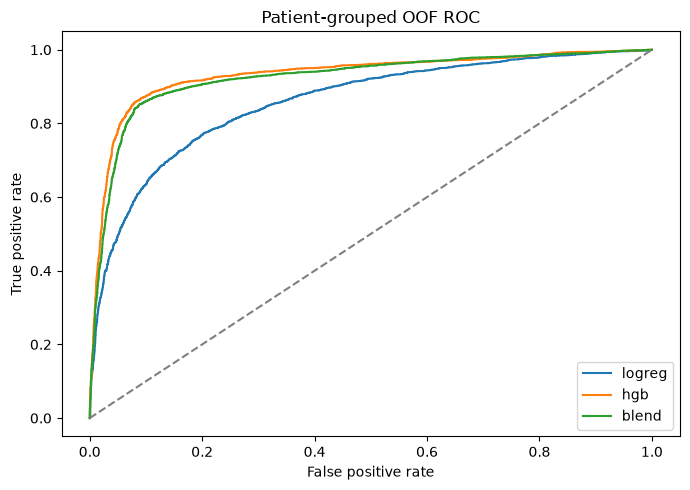

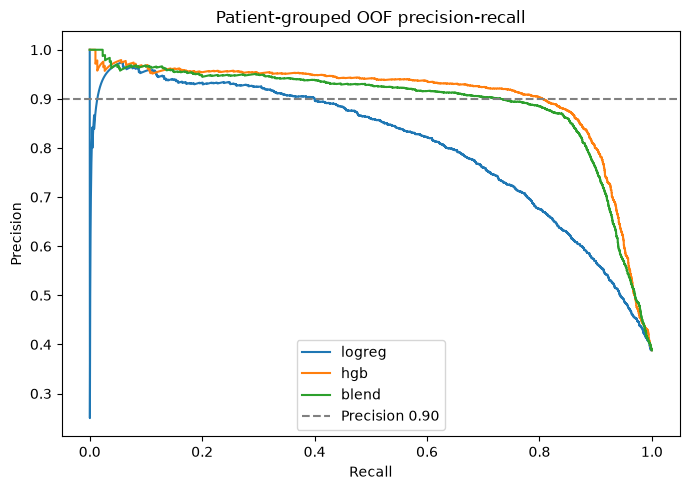

In [55]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

from src.config import CLEAN_DIR
from src.model import center_holdout, get_features, make_models, metrics, oof_predictions

train_stage4 = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
feature_frame = get_features(train_stage4)
target = train_stage4["y"].astype(int)
patient_groups = train_stage4["patient_id"]

print(f"Features ({len(feature_frame.columns)}): {list(feature_frame.columns)}")
model_templates = make_models()
oof_probability = oof_predictions(model_templates, feature_frame, target, patient_groups)
oof_metrics = pd.DataFrame(
    {name: metrics(target, probability) for name, probability in oof_probability.items()}
).T
display(oof_metrics)

center_metrics = center_holdout(model_templates, train_stage4, feature_frame, target)
display(center_metrics)

best_model_name = max(
    oof_metrics.index,
    key=lambda name: (
        oof_metrics.loc[name, "recall_at_precision"],
        oof_metrics.loc[name, "roc_auc"],
    ),
)
best_model = model_templates[best_model_name]
print(
    f"Chosen model: {best_model_name}; highest OOF recall at precision >= 0.90 "
    f"({oof_metrics.loc[best_model_name, 'recall_at_precision']:.4f}); "
    f"ROC-AUC breaks ties. ROC-AUC={oof_metrics.loc[best_model_name, 'roc_auc']:.4f}."
)

figure_dir = Path.cwd().resolve()
if figure_dir.name == "notebooks":
    figure_dir = figure_dir.parent
figure_dir = figure_dir / "evidence" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axis = plt.subplots(figsize=(7, 5))
for name, probability in oof_probability.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(target, probability)
    axis.plot(false_positive_rate, true_positive_rate, label=name)
axis.plot([0, 1], [0, 1], linestyle="--", color="gray")
axis.set(xlabel="False positive rate", ylabel="True positive rate", title="Patient-grouped OOF ROC")
axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "stage6_roc.png", dpi=160)
plt.show()
plt.close(fig)

fig, axis = plt.subplots(figsize=(7, 5))
for name, probability in oof_probability.items():
    precision_curve, recall_curve, _ = precision_recall_curve(target, probability)
    axis.plot(recall_curve, precision_curve, label=name)
axis.axhline(0.90, linestyle="--", color="gray", label="Precision 0.90")
axis.set(xlabel="Recall", ylabel="Precision", title="Patient-grouped OOF precision-recall")
axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "stage6_precision_recall.png", dpi=160)
plt.show()
plt.close(fig)

# 5 Threshold

,threshold,precision,recall,shifted_precision,bootstrap_p05,TP,FP
51,0.81,0.921431,0.709281,0.822091,0.911827,2369,202
52,0.82,0.924016,0.702695,0.827331,0.915029,2347,193
53,0.83,0.925600,0.692814,0.830562,0.917117,2314,186
54,0.84,0.926879,0.679341,0.833180,0.918106,2269,179
55,0.85,0.929648,0.664671,0.838881,0.920960,2220,168
56,0.86,0.930680,0.651198,0.841017,0.921957,2175,162
57,0.87,0.931416,0.630240,0.842543,0.922686,2105,155
58,0.88,0.934892,0.610479,0.849798,0.926470,2039,142
59,0.89,0.937203,0.589820,0.854658,0.928834,1970,132
60,0.90,0.939970,0.562575,0.860522,0.930975,1879,120


Chosen threshold: 0.95
Relaxed condition: bootstrap p05 >= 0.90; shifted precision >= 0.88
Expected precision: 0.9517
Expected recall: 0.3362
False alarms per extra cancer caught: 0.1536
OOF predicted M share: 0.1371


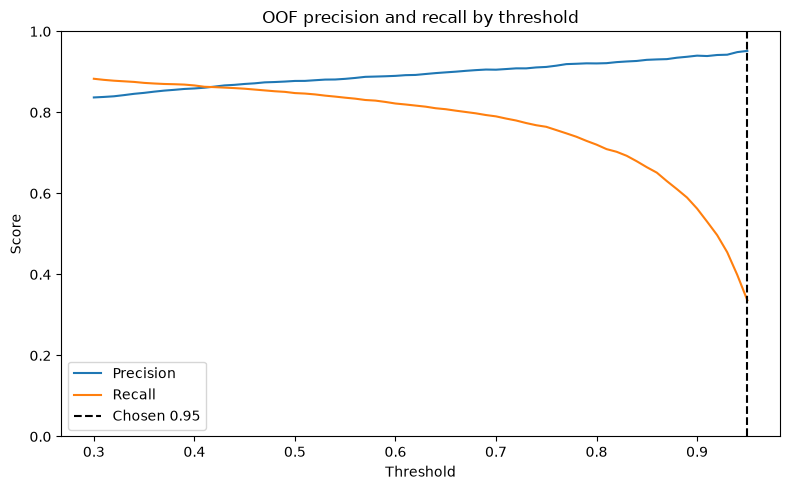

In [56]:
import matplotlib.pyplot as plt

from src.model import choose_threshold

threshold_table, chosen_threshold, relaxed_condition, false_alarms_per_extra_cancer = choose_threshold(
    target, oof_probability[best_model_name], patient_groups
)
chosen_index = int(threshold_table.index[threshold_table["threshold"].eq(chosen_threshold)][0])
nearby_thresholds = threshold_table.iloc[max(0, chosen_index - 14):chosen_index + 1]
display(nearby_thresholds)

chosen_metrics = threshold_table.loc[threshold_table["threshold"].eq(chosen_threshold)].iloc[0]
oof_predicted_m_share = float((oof_probability[best_model_name] >= chosen_threshold).mean())
print(f"Chosen threshold: {chosen_threshold:.2f}")
print(f"Relaxed condition: {relaxed_condition}")
print(f"Expected precision: {chosen_metrics['precision']:.4f}")
print(f"Expected recall: {chosen_metrics['recall']:.4f}")
print(f"False alarms per extra cancer caught: {false_alarms_per_extra_cancer:.4f}")
print(f"OOF predicted M share: {oof_predicted_m_share:.4f}")

fig, axis = plt.subplots(figsize=(8, 5))
axis.plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
axis.plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
axis.axvline(chosen_threshold, linestyle="--", color="black", label=f"Chosen {chosen_threshold:.2f}")
axis.set(xlabel="Threshold", ylabel="Score", ylim=(0, 1), title="OOF precision and recall by threshold")
axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "stage6_threshold.png", dpi=160)
plt.show()
plt.close(fig)

# 6 Submission

In [57]:
import importlib

import src.config as project_config
import src.model as stage6_model

importlib.reload(project_config)
importlib.reload(stage6_model)
TEAM_NAME = project_config.TEAM_NAME
make_submission = stage6_model.make_submission

test_stage4 = pd.read_csv(CLEAN_DIR / "test_stage4.csv", parse_dates=["exam_date"])
submission = make_submission(
    best_model,
    feature_frame,
    target,
    test_stage4,
    chosen_threshold,
    TEAM_NAME,
)
print(f"OOF predicted M share: {oof_predicted_m_share:.4f}")
print(f"Test predicted M share: {(submission['predicted_label'] == 'M').mean():.4f}")
print("First five submission rows:")
display(submission.head())
print("Predicted class counts:")
display(submission["predicted_label"].value_counts().rename_axis("predicted_label").to_frame("count"))

Submission checks passed: 2884 rows, 3 columns, IDs unique and aligned, no NaN.
Test predicted M share: 0.0610
OOF predicted M share: 0.1371
Test predicted M share: 0.0610
First five submission rows:


,patient_id,predicted_label,predicted_prob
0,912511,B,0.035453
1,910569,B,0.060641
2,910709,B,0.077854
3,911138,B,0.026167
4,911095,B,0.912922


Predicted class counts:


,count
predicted_label,
B,2708
M,176


## What we found (modelling, threshold, submission)
- Three models, 5-fold grouped by patient, out-of-fold: logistic regression AUC 0.858 / recall at 90% precision 0.40; HistGradientBoosting AUC 0.932 / recall 0.81; blend AUC 0.923 / recall 0.73. We chose HistGradientBoosting (best on both).
- Leave-one-centre-out AUC for hgb: Site A 0.932, Site B 0.931, Site C 0.922. The model does not depend on a single site.
- Threshold 0.95: out-of-fold precision 0.952, recall 0.336; about 0.15 false alarms per extra cancer caught. The safety checks (shifted to 20% malignant, bootstrap) could not all be met, so two conditions were relaxed.
- The first submission passes the format checks: 2,884 rows, one per patient, labels M/B, probabilities in [0,1]. It labels 6.1% of test patients malignant versus 13.7% in out-of-fold, consistent with the test set having fewer cancers (we did not tune on this).
- This threshold is deliberately cautious. We will review it after improving the model.